# Phishing URL classifier

This notebook trains only on features extracted from the URL string. It never visits a URL, reads HTML, or uses PhiUSIIL’s webpage-derived columns. Label `1` always means phishing.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = Path.cwd().resolve()
while not (MODEL_DIR / "src").is_dir():
    if MODEL_DIR.parent == MODEL_DIR:
        raise RuntimeError("Run this notebook from inside the model directory tree.")
    MODEL_DIR = MODEL_DIR.parent
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_preparation import prepare_url_dataset
from src.train_models import train_url_model

sns.set_theme(style='whitegrid')

## Prepare and inspect safe URL data

PhiUSIIL’s original `1 = legitimate` and `0 = phishing` convention is inverted once during preprocessing to ScaMail’s `0 = legitimate`, `1 = phishing` convention. The processed file retains only `url` and `label`.

{'before_cleaning': {'records': 235795, 'class_distribution': {'0': 134850, '1': 100945}}, 'after_cleaning': {'records': 235370, 'class_distribution': {'0': 134850, '1': 100520}}, 'removed_exact_duplicates_or_empty': 425, 'source_label_mapping': {'1': 'legitimate -> 0', '0': 'phishing -> 1'}}
Shape: (235370, 2)


,url,label
0,https://www.southbankmosaics.com,0
1,https://www.uni-mainz.de,0
2,https://www.voicefmradio.co.uk,0
3,https://www.sfnmjournal.com,0
4,https://www.rewildingargentina.org,0


Missing values:
 url      0
label    0
dtype: int64
Duplicate URLs: 0
Class distribution:
 label
legitimate    134850
phishing      100520
Name: count, dtype: int64


C:\Users\Sabyasachi Samanta\AppData\Local\Temp\ipykernel_9212\1826146838.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  sns.countplot(data=urls, x='label', ax=axes[0]); axes[0].set_xticklabels(['legitimate', 'phishing'])


,label,url
0,0,https://www.southbankmosaics.com
1,0,https://www.uni-mainz.de
2,0,https://www.voicefmradio.co.uk
11,1,http://www.teramill.com
20,1,http://www.f0519141.xsph.ru
21,1,http://www.shprakserf.gq


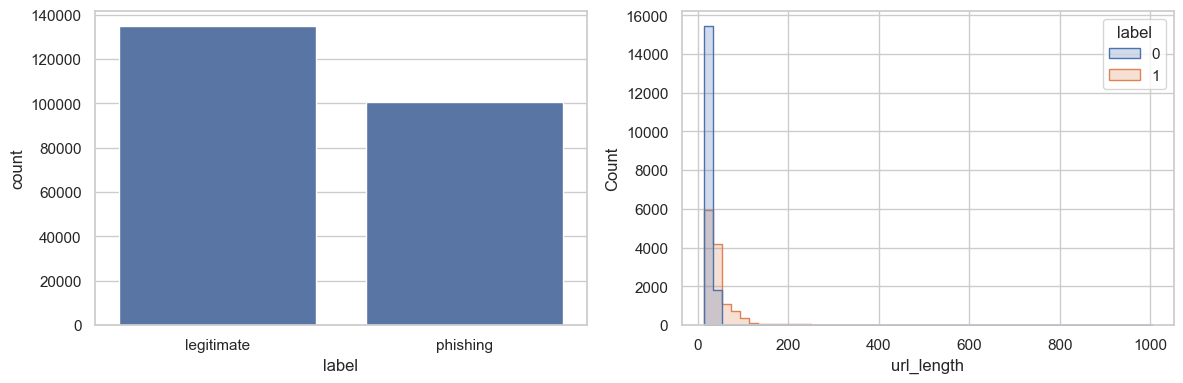

In [2]:
urls, cleaning_report = prepare_url_dataset(save=True)
print(cleaning_report)
print('Shape:', urls.shape)
display(urls.head())
print('Missing values:\n', urls.isna().sum())
print('Duplicate URLs:', urls.duplicated('url').sum())
print('Class distribution:\n', urls.label.value_counts().rename(index={0: 'legitimate', 1: 'phishing'}))
urls['url_length'] = urls.url.str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=urls, x='label', ax=axes[0]); axes[0].set_xticklabels(['legitimate', 'phishing'])
sns.histplot(data=urls.sample(min(30000, len(urls)), random_state=42), x='url_length', hue='label', bins=50, element='step', ax=axes[1])
plt.tight_layout()
display(urls.groupby('label').head(3)[['label', 'url']])

## Offline feature engineering and domain-grouped evaluation

`urllib.parse` and `tldextract` derive URL length, host structure, digits, HTTPS, path/query properties, suspicious words, punycode, and entropy without a network request. Public-suffix-aware registered domains are used as groups: the same registered domain cannot occur in more than one split. This is stricter than a random URL split, although it can shift the class balance because domains—not individual URLs—are assigned together.

Candidates: ['RandomForestClassifier']
xgboost was not installed; RandomForestClassifier is the selected documented baseline.
Split sizes: {'train': 148453, 'validation': 45028, 'test': 41889}
Class distributions: {'train': {'0': 81123, '1': 67330}, 'validation': {'0': 26781, '1': 18247}, 'test': {'0': 26946, '1': 14943}}
Shared registered domains: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
Validation metrics:


accuracy                      0.996225
precision_scam_or_phishing    0.997852
recall_scam_or_phishing       0.992821
f1_scam_or_phishing            0.99533
pr_auc                        0.997863
dtype: object

Held-out test metrics:


accuracy                      0.995751
precision_scam_or_phishing    0.997842
recall_scam_or_phishing        0.99023
f1_scam_or_phishing           0.994021
pr_auc                        0.997221
dtype: object

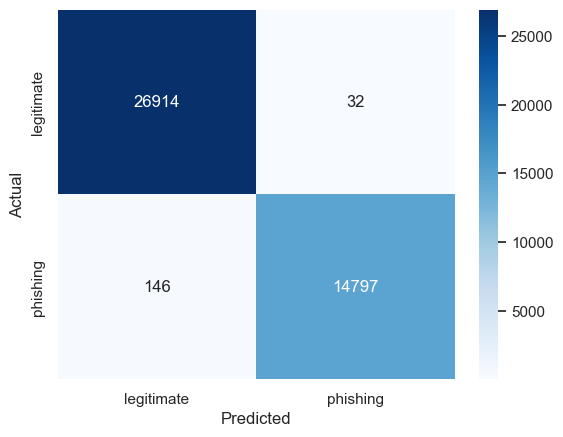

              precision    recall  f1-score       support
legitimate     0.994605  0.998812  0.996704  26946.000000
malicious      0.997842  0.990230  0.994021  14943.000000
accuracy       0.995751  0.995751  0.995751      0.995751
macro avg      0.996223  0.994521  0.995363  41889.000000
weighted avg   0.995759  0.995751  0.995747  41889.000000


In [3]:
result = train_url_model()
print('Candidates:', result['model_candidates'])
print(result['xgboost_reason'])
print('Split sizes:', result['split_sizes'])
print('Class distributions:', result['split_class_distributions'])
print('Shared registered domains:', result['shared_registered_domains'])
print('Validation metrics:')
display(pd.Series(result['validation_metrics']).drop(['classification_report', 'confusion_matrix']))
print('Held-out test metrics:')
display(pd.Series(result['test_metrics']).drop(['classification_report', 'confusion_matrix']))
sns.heatmap(result['test_metrics']['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=['legitimate', 'phishing'], yticklabels=['legitimate', 'phishing'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()
print(pd.DataFrame(result['test_metrics']['classification_report']).T)

## Feature importance and error analysis

Random Forest importance indicates which engineered URL-string features the fitted model used most. Importance is association, not causation. Examine false positives (legitimate URLs flagged as phishing) and false negatives (phishing URLs missed) before changing a decision threshold.

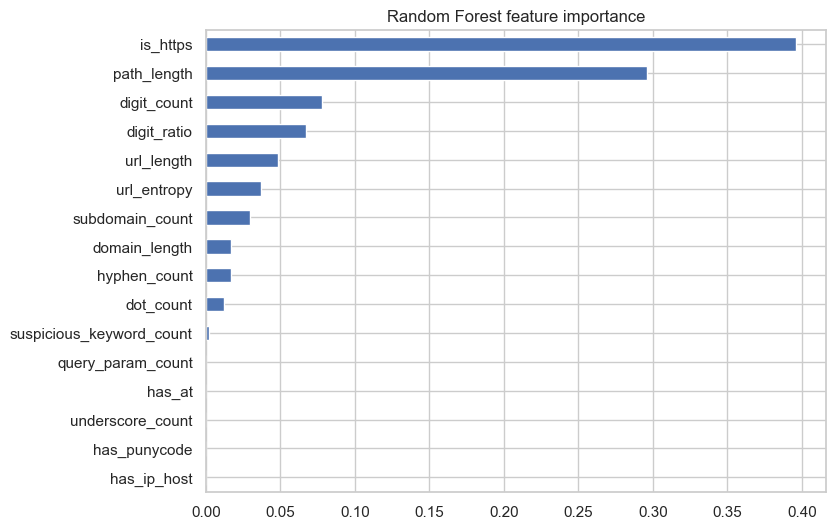

,url,actual,prediction,probability
2037,https://www.diecezjawroclawsko-szczecinska.pl,0,1,0.621548
2138,https://www.christoph-graupner-gesellschaft.de,0,1,0.713069
3464,https://www.puzzlemaker.discoveryeducation.com,0,1,0.749786
3899,https://www.112112ww.com,0,1,0.796836
5964,https://www.19thcircuitcourt.state.il.us,0,1,0.745593
6205,https://www.industrydocuments.ucsf.edu,0,1,0.562529
7524,https://www.180360.com,0,1,0.883125
9289,https://www.sc18.supercomputing.org,0,1,0.664787
11773,https://www.check24-partnerprogramm.de,0,1,0.618388
12094,https://www.shrewsbury24campaign.org.uk,0,1,0.555910


,url,actual,prediction,probability
343,https://www.steamncommurity.ru,1,0,0.012275
1458,https://duenorthsafaris.portfoliobox.net,1,0,0.007924
1560,https://www.kuronekoyamato.ok-hospital.com,1,0,0.178266
2065,https://www.dipartimento-revisone.com,1,0,0.017587
2289,https://www.niktell.com,1,0,0.008166
2335,https://www.xn--ingenieurbro-brasnic-yec.de,1,0,0.080560
3436,https://www.jpmodafeminina.com.br,1,0,0.006510
3966,https://www.wellfedintelligence.com,1,0,0.005679
4410,https://host-authoritastive.wikaba.com,1,0,0.128675
4553,https://www.3659dd.cc,1,0,0.349267


In [4]:
importance = pd.Series(result['feature_importance']).sort_values()
importance.plot.barh(figsize=(8, 6), title='Random Forest feature importance')
plt.show()
display(result['error_analysis']['false_positives'])
display(result['error_analysis']['false_negatives'])

## Saved pipeline and inference

The persisted pipeline contains the URL feature transformer and fitted Random Forest. `predict_proba(...)[..., 1]` is the phishing probability; flags are derived directly from actual URL features.

In [5]:
from src.url_predictor import predict_url
artifact = MODEL_DIR / 'saved_model' / 'url_phishing_pipeline.joblib'
print('Saved:', artifact, artifact.exists())
predict_url('http://secure-login.verify-account.example/confirm?user=123')

Saved: C:\Coding\Projects\ScaMail AI\model\saved_model\url_phishing_pipeline.joblib True


{'prob': 1.0,
 'prediction': 'phishing',
 'flags': ['suspicious_keywords', 'not_https']}